In [ ]:
%matplotlib inline

# Solution 2 — Sensitivity to alignment errors

Apply the same random final-doublet offsets to the nominal and desqueezed optics. Compare the uncorrected closed orbits.

The two optics have the same tunes and corrected linear chromaticities. Keep the sextupoles active for this comparison.

### Load the lattice

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

env = xt.load('fccee_z.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)

### Misalign the final doublets

Select the QD0 and QF1 sections on both sides of all four IPs. Apply independent horizontal and vertical Gaussian shifts with 5 µm RMS, using a fixed random seed.

In [2]:
table = line.get_table()
quad_names = table.rows[r'(qd0[abc]|qf1[abcd])[lr]\.[0-3]'].name

rng = np.random.default_rng(2026)
sigma_shift = 5e-6  # m
shift_x = rng.normal(scale=sigma_shift, size=len(quad_names))
shift_y = rng.normal(scale=sigma_shift, size=len(quad_names))

for name, shx, shy in zip(quad_names, shift_x, shift_y):
    line[name].shift_x = shx
    line[name].shift_y = shy

### Nominal orbit

In [3]:
env.vars.load('optics_nominal.json')
tw_nominal = line.twiss4d(only_orbit=True)

### Desqueezed orbit

Loading another strength file leaves the same quadrupole offsets in place.

In [4]:
env.vars.load('optics_desqueezed.json')
tw_desqueezed = line.twiss4d(only_orbit=True)

### Horizontal closed orbit

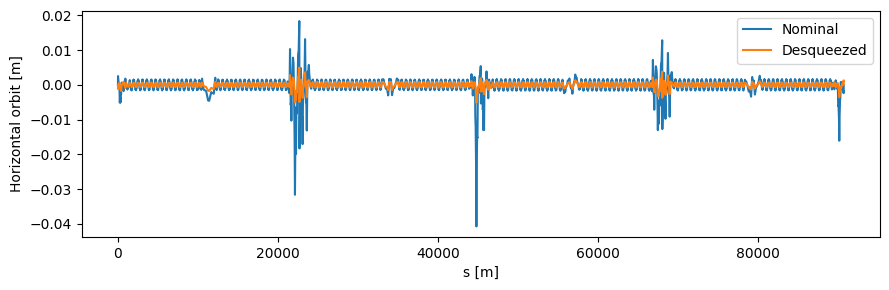

In [5]:
plt.figure(figsize=(9, 3))
plt.plot(tw_nominal.s, tw_nominal.x, label='Nominal')
plt.plot(tw_desqueezed.s, tw_desqueezed.x, label='Desqueezed')
plt.xlabel('s [m]')
plt.ylabel('Horizontal orbit [m]')
plt.legend()
plt.tight_layout()

### Vertical closed orbit

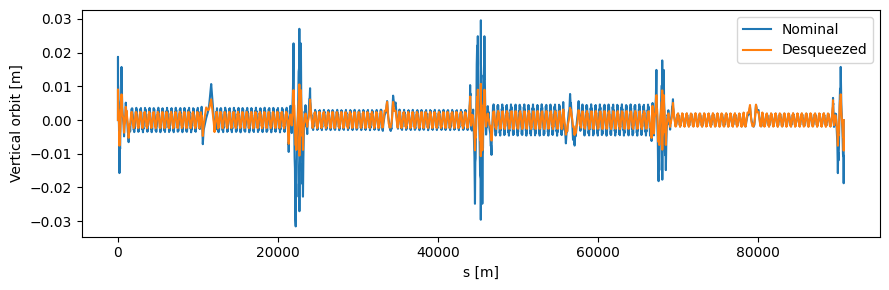

In [6]:
plt.figure(figsize=(9, 3))
plt.plot(tw_nominal.s, tw_nominal.y, label='Nominal')
plt.plot(tw_desqueezed.s, tw_desqueezed.y, label='Desqueezed')
plt.xlabel('s [m]')
plt.ylabel('Vertical orbit [m]')
plt.legend()
plt.tight_layout()

Which optics is more tolerant to these alignment errors? How does this relate to the beta functions in the final doublets?